# Group 03 — Week 2: Design & Implement Assigned Augmentation
**Topic:** Geometric Augmentation — Scaling / Zoom
**This week:** design Low/Medium/High scaling-intensity levels with justification, implement the augmentation (with correct bounding-box rescaling), and generate before/after sample grids for visual inspection.

This builds directly on Week 1 — same dataset split (`random_state=42`, so it's reproducible), same 6 classes, same `640x640` target size.


## 1. Setup

In [1]:
!pip install -q ultralytics opencv-python-headless matplotlib
import os, glob, cv2, random
import numpy as np
import matplotlib.pyplot as plt


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 401.6 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.0/91.0 kB 6.1 MB/s eta 0:00:00


## 2. Reload Week 1's dataset split
Upload the `baseline_dataset.zip` you downloaded at the end of Week 1 (the one containing `dataset_split/` with `train/images`, `train/labels`, `val/`, `test/`, and `data.yaml`). This restores the exact same split you validated last week — no need to rebuild it from the raw Kaggle zip.


In [2]:
from google.colab import files
print("Select your Week 1 baseline_dataset.zip...")
uploaded = files.upload()
zip_filename = list(uploaded.keys())[0]


Select your Week 1 baseline_dataset.zip...


Saving baseline_dataset.zip to baseline_dataset.zip


In [4]:
!find /content -maxdepth 3 -iname "dataset_split"

/content/content/dataset_split


In [5]:
import zipfile

with zipfile.ZipFile(zip_filename, 'r') as zf:
    zf.extractall('/content')

DATASET_ROOT = '/content/content/dataset_split'
CLASS_NAMES = ['car', 'threewheel', 'bus', 'truck', 'motorbike', 'van']  # same order as Week 1 — verified

train_images = sorted(glob.glob(f'{DATASET_ROOT}/train/images/*'))
print(f"Restored dataset. Train images found: {len(train_images)}")


Restored dataset. Train images found: 2100


## 3. Image-Processing Theory — Scaling / Zoom (for Report Section 2)

**What it models:** vehicles at different distances from the camera occupy different fractions of the image frame — a nearby vehicle appears large, a distant one appears small. Scaling/zoom augmentation simulates this by resizing the image about its center and either **cropping** (zoom-in, simulating a closer vehicle) or **padding** (zoom-out, simulating a farther vehicle), while keeping the output canvas fixed at 640×640.

**The transform.** For a scale factor `s`:
- **Image:** resize the `640x640` image by factor `s`, then:
  - if `s ≥ 1` (zoom in): center-crop the enlarged image back down to `640x640`
  - if `s < 1` (zoom out): center-pad the shrunk image back up to `640x640` (grey padding, matching YOLO's standard letterbox color)
- **Bounding boxes:** since the scaling is about the image center, YOLO's *normalized* `(x_center, y_center, width, height)` coordinates transform directly:

```
x_center' = 0.5 + (x_center - 0.5) * s
y_center' = 0.5 + (y_center - 0.5) * s
width'    = width  * s
height'   = height * s
```

Any box that falls fully outside the `[0,1]` frame after a zoom-in crop is dropped; boxes that are partially clipped are trimmed to the visible region. This mirrors exactly what would happen physically if a camera zoomed in and part of a vehicle left the frame.


## 4. Implement the augmentation function

In [6]:
def load_yolo_labels(label_path):
    boxes = []
    if os.path.exists(label_path):
        with open(label_path) as f:
            for line in f:
                parts = line.split()
                if len(parts) < 5:
                    continue
                cls, xc, yc, w, h = parts[:5]
                boxes.append((int(cls), float(xc), float(yc), float(w), float(h)))
    return boxes

def save_yolo_labels(label_path, boxes):
    with open(label_path, 'w') as f:
        for cls, xc, yc, w, h in boxes:
            f.write(f"{cls} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}\n")

def scale_zoom_augment(img, boxes, scale, pad_color=(114, 114, 114)):
    """Scale/zoom an image about its center and rescale YOLO-format boxes to match.

    scale > 1  -> zoom IN  (simulates a closer vehicle): resize up, then center-crop
    scale < 1  -> zoom OUT (simulates a farther vehicle): resize down, then center-pad
    scale == 1 -> no change
    """
    h, w = img.shape[:2]
    new_w, new_h = max(1, int(round(w * scale))), max(1, int(round(h * scale)))
    resized = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_LINEAR)

    if scale >= 1:
        x0 = (new_w - w) // 2
        y0 = (new_h - h) // 2
        out_img = resized[y0:y0 + h, x0:x0 + w]
    else:
        out_img = np.full((h, w, 3), pad_color, dtype=np.uint8)
        x0 = (w - new_w) // 2
        y0 = (h - new_h) // 2
        out_img[y0:y0 + new_h, x0:x0 + new_w] = resized

    new_boxes = []
    for cls, xc, yc, bw, bh in boxes:
        xc2 = 0.5 + (xc - 0.5) * scale
        yc2 = 0.5 + (yc - 0.5) * scale
        bw2 = bw * scale
        bh2 = bh * scale

        x1, y1 = xc2 - bw2 / 2, yc2 - bh2 / 2
        x2, y2 = xc2 + bw2 / 2, yc2 + bh2 / 2
        x1c, y1c = max(0.0, x1), max(0.0, y1)
        x2c, y2c = min(1.0, x2), min(1.0, y2)

        if x2c <= x1c or y2c <= y1c:
            continue  # box left the frame entirely after zoom-in crop

        new_boxes.append((cls, (x1c + x2c) / 2, (y1c + y2c) / 2, x2c - x1c, y2c - y1c))

    return out_img, new_boxes

print("scale_zoom_augment() ready.")


scale_zoom_augment() ready.


## 5. Define Low / Medium / High intensity levels — with justification

Each intensity is a **range** of scale factors, `s ~ Uniform(low, high)`, applied randomly per image during training (so the model sees varied zoom levels, not one fixed value). Wider ranges = more aggressive simulated distance variation = harder training signal.

| Intensity | Scale range | Justification |
|---|---|---|
| **Low** | `[0.90, 1.10]` | ±10% size change — mimics small natural distance variation between similarly-positioned vehicles (e.g. adjacent lanes). A gentle augmentation that shouldn't destabilise training. |
| **Medium** | `[0.75, 1.25]` | ±25% — approximates the apparent size difference between a vehicle one car-length closer/farther, a common real-world range in traffic camera footage. |
| **High** | `[0.60, 1.40]` | ±40% — deliberately aggressive, simulating near-field vs. far-field vehicles (e.g. a truck close to the camera vs. one near the vanishing point of the road). Tests whether YOLO's multi-scale detection heads degrade under a wide, unrealistic-at-the-extreme size range. |

For the **before/after visual samples** below, we use the two extremes of each range (min = zoom-out, max = zoom-in) so the effect is visible; during actual training (Week 3) the factor is re-sampled randomly per image from the full range.


In [7]:
INTENSITY_LEVELS = {
    'Low':    (0.90, 1.10),
    'Medium': (0.75, 1.25),
    'High':   (0.60, 1.40),
}
for name, (lo, hi) in INTENSITY_LEVELS.items():
    print(f"{name}: scale range [{lo}, {hi}]  (zoom-out extreme={lo}, zoom-in extreme={hi})")


Low: scale range [0.9, 1.1]  (zoom-out extreme=0.9, zoom-in extreme=1.1)
Medium: scale range [0.75, 1.25]  (zoom-out extreme=0.75, zoom-in extreme=1.25)
High: scale range [0.6, 1.4]  (zoom-out extreme=0.6, zoom-in extreme=1.4)


## 6. Generate before/after sample grids (one figure per intensity)
For a handful of sample training images, show: **original**, **zoomed-out extreme**, **zoomed-in extreme** — with bounding boxes drawn, so you can visually confirm the boxes track the vehicles correctly through the transform.


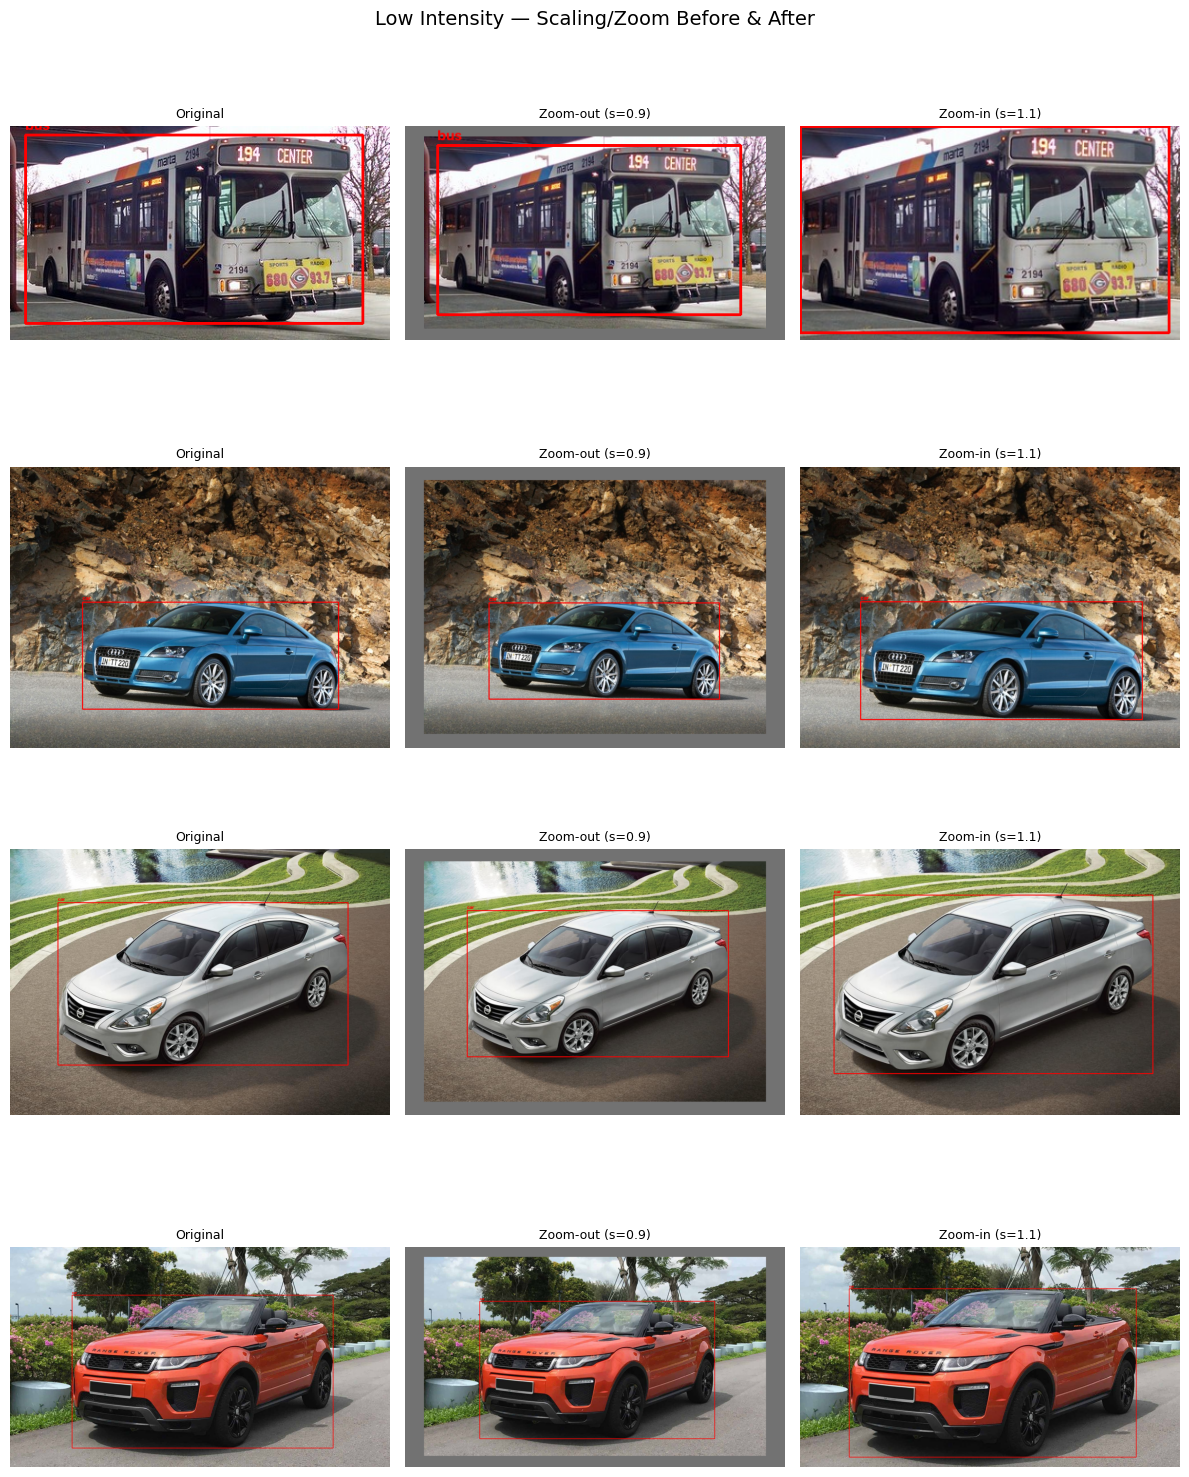

Saved: /content/before_after_samples/low_intensity_grid.png


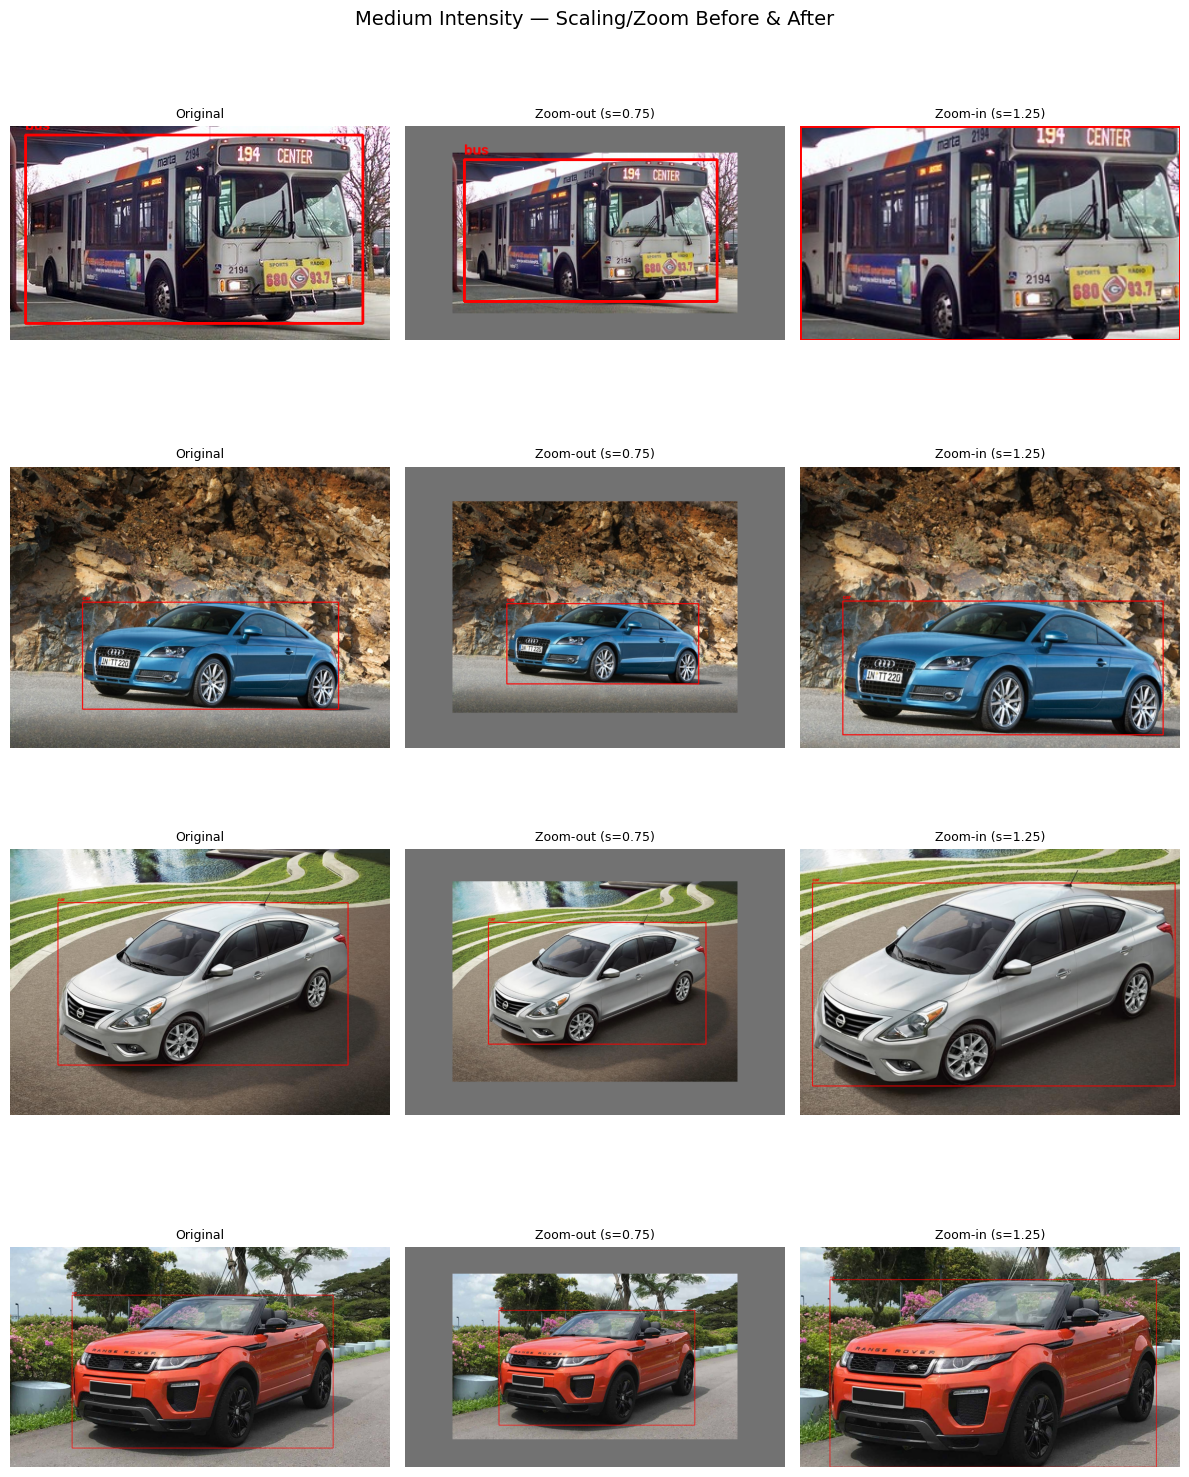

Saved: /content/before_after_samples/medium_intensity_grid.png


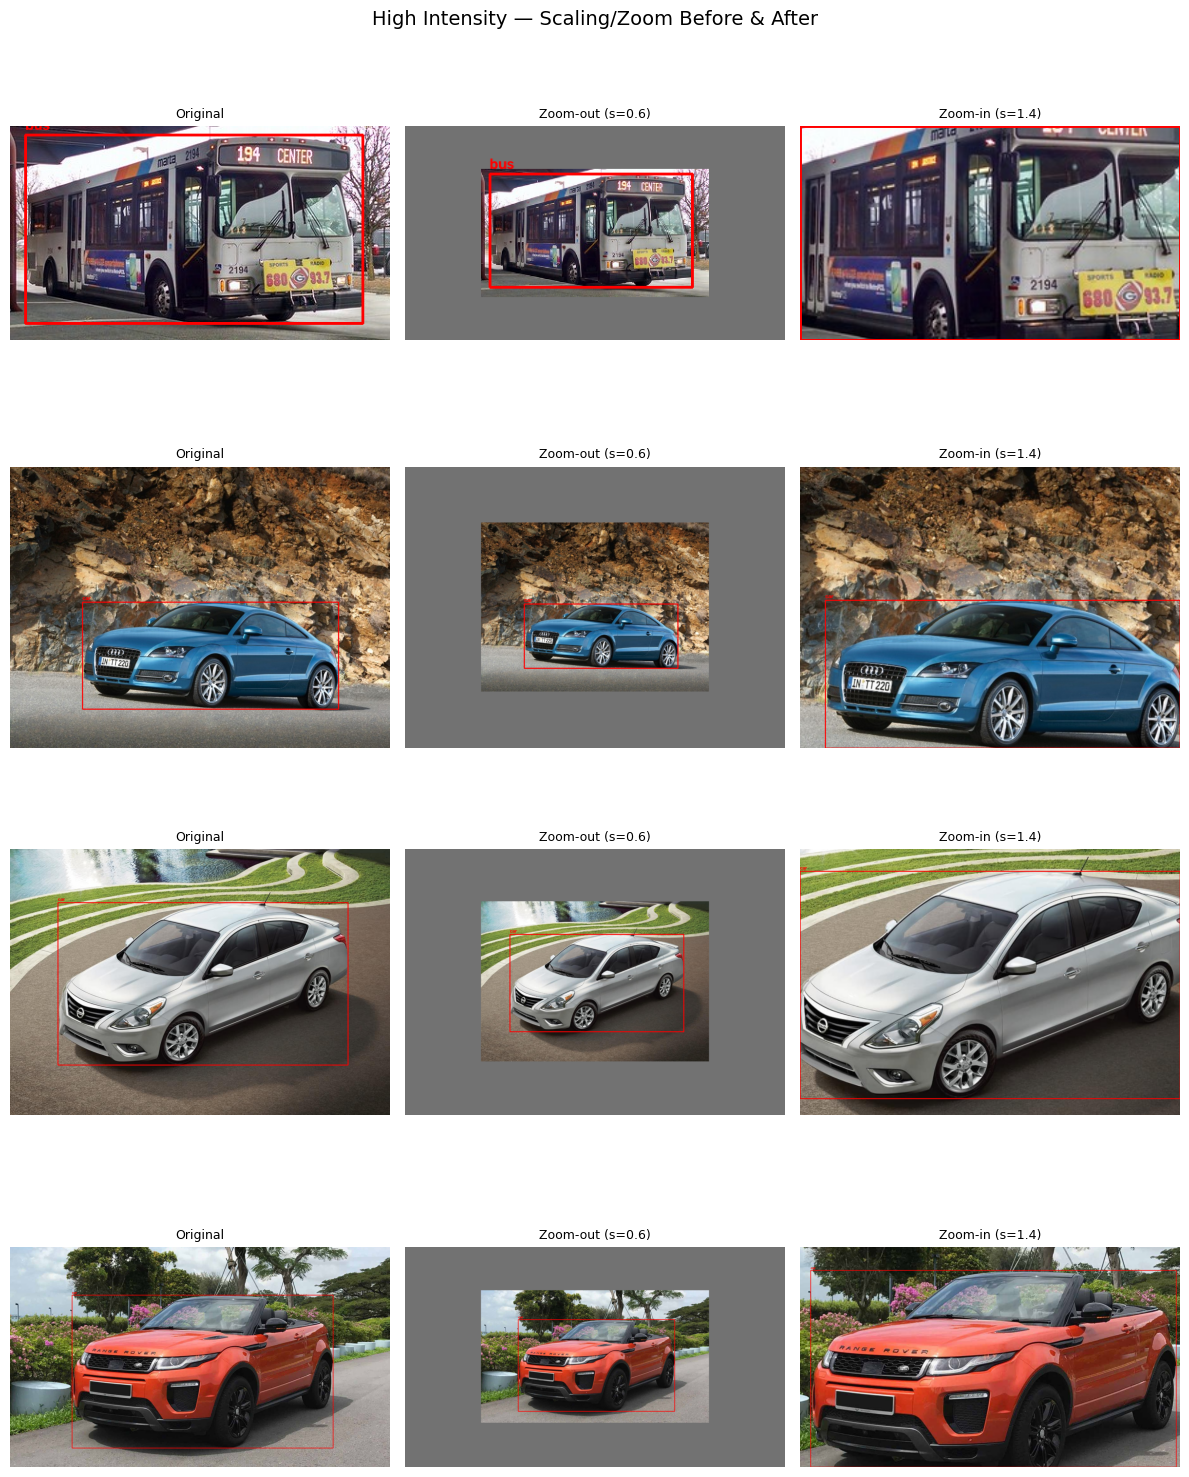

Saved: /content/before_after_samples/high_intensity_grid.png


In [8]:
def draw_boxes(img, boxes, class_names, color=(255, 0, 0)):
    img = img.copy()
    h, w = img.shape[:2]
    for cls, xc, yc, bw, bh in boxes:
        x1, y1 = int((xc - bw/2) * w), int((yc - bh/2) * h)
        x2, y2 = int((xc + bw/2) * w), int((yc + bh/2) * h)
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
        label = class_names[cls] if cls < len(class_names) else str(cls)
        cv2.putText(img, label, (x1, max(y1 - 5, 0)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)
    return img

random.seed(42)
sample_paths = random.sample(train_images, 4)

os.makedirs('/content/before_after_samples', exist_ok=True)

for intensity, (lo, hi) in INTENSITY_LEVELS.items():
    fig, axes = plt.subplots(4, 3, figsize=(12, 16))
    for row, img_path in enumerate(sample_paths):
        base = os.path.splitext(os.path.basename(img_path))[0]
        label_path = img_path.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt'

        img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        boxes = load_yolo_labels(label_path)

        img_out, boxes_out = scale_zoom_augment(img, boxes, hi)   # zoom-in extreme
        img_in, boxes_in = scale_zoom_augment(img, boxes, lo)     # zoom-out extreme

        panels = [
            (draw_boxes(img, boxes, CLASS_NAMES), 'Original'),
            (draw_boxes(img_in, boxes_in, CLASS_NAMES), f'Zoom-out (s={lo})'),
            (draw_boxes(img_out, boxes_out, CLASS_NAMES), f'Zoom-in (s={hi})'),
        ]
        for col, (panel_img, title) in enumerate(panels):
            axes[row, col].imshow(panel_img)
            axes[row, col].set_title(title, fontsize=9)
            axes[row, col].axis('off')

    fig.suptitle(f'{intensity} Intensity — Scaling/Zoom Before & After', fontsize=14)
    plt.tight_layout()
    out_path = f'/content/before_after_samples/{intensity.lower()}_intensity_grid.png'
    plt.savefig(out_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: {out_path}")


## 7. Package Week 2 deliverables for submission
Zips the augmentation code context is already in this notebook, plus the before/after sample grids for all 3 intensities, ready for the weekly report and for download.


In [9]:
!zip -r /content/week2_augmentation_deliverables.zip /content/before_after_samples

from google.colab import files
files.download('/content/week2_augmentation_deliverables.zip')


  adding: content/before_after_samples/ (stored 0%)
  adding: content/before_after_samples/medium_intensity_grid.png (deflated 0%)
  adding: content/before_after_samples/low_intensity_grid.png (deflated 0%)
  adding: content/before_after_samples/high_intensity_grid.png (deflated 1%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Next week (Week 3) preview
Week 3 trains each YOLO version (v8n, v11n, v26n) on every augmented dataset version, with dataset split, image size, epochs, batch size and hardware kept identical to the Week 1 baseline. That means: for each intensity level, apply `scale_zoom_augment()` (with `s` re-sampled per image from that intensity's range) across the **entire** train split, save the augmented images+labels to a new folder, write a matching `data.yaml`, and train — repeating the exact same 3-model baseline training loop from Week 1 against each new augmented dataset.
